# Model and threshold selection by out-of-fold net PnL with `PurgedKFold` — development selection, then one final test

This notebook reuses, **without reimplementing**, everything from `research/primary_straegy/test_primary_strategies_quantforge.ipynb`:

* the strategy `quant_forge.strategies.Strategies.STRATEGY_432_BTC` (`fee_bps=5`, library defaults) on a volume-bar dataset chosen by one route variable (`DATASET_NAME`);
* the target `trade_return > 0` (net profit after the simulator's costs), the decision-time feature list and the two classifiers
  (median-impute + scale + L2 logistic regression, and `CatBoostClassifier`);
* the chronological 70 / 30 split (`train_test_split(..., test_size=0.30, shuffle=False)`), the purge rule `exit_time < test_start`,
  and the equity / economics function `plot_strategy_equity` (copied unchanged);
* `quant_forge.validation.PurgedKFold` for every cross-validation split.

Two classifiers are added with fixed, a-priori hyper-parameters (no search): `RandomForestClassifier` and `GradientBoostingClassifier`.

**Selection score — fixed-notional event PnL.** For a model and a threshold `t`, with `p` the out-of-fold probability of the profitable class,

    score(t) = sum( (p >= t) * net_trade_pnl ),       net_trade_pnl = FIXED_NOTIONAL * trade_return

`trade_return` is the library's *net* return of one trade: the simulator's fees are already inside it, so nothing is subtracted again. Every candidate trades the same
`FIXED_NOTIONAL` per accepted event, and a rejected event contributes exactly zero. The score is a plain **sum of event PnLs** — it is *not* a capital-constrained portfolio return, it does not compound, and it is not an average return
of the accepted trades. Two model-free alternatives compete on the same score: **accept-all** (the unfiltered strategy) and **reject-all** (score 0); if either wins, that is the reported outcome, and no trades are forced.

**Protocol**

| Step | Data | What happens |
|---|---|---|
| 1 | all trades | strategy run, chronological split into *development* (first 70 %) and *final test* (last 30 %); development events whose label interval reaches into the test period are purged |
| 2 | development only | all four models on **identical** `PurgedKFold` splits (with embargo); preprocessing is fitted inside each fold on its training rows; every model/pipeline is cloned per fold |
| 3 | development only | pooled out-of-fold (OOF) probabilities of the profitable class; OOF fixed-notional PnL on one shared threshold grid, pooled and per fold |
| 4 | development only | the candidate (model × threshold, accept-all, reject-all) with the highest pooled OOF net PnL is selected (deterministic tie-break); F1, precision, recall, log loss are diagnostics only |
| 5 | development → test | the selected pipeline is refitted on **all** eligible development events, its threshold is frozen, and the final test is evaluated **once** |

**What this is not.** The OOF numbers of steps 3–4 are *selection* statistics: they are the maximum over several models × thresholds, so they are
optimistically biased and are not an independent estimate of the selected configuration. Only step 5 is untouched by selection, and the test set is
small. Maximising PnL on development data is a selection rule, not a forecast of future profit. The final test is never used to choose features, models, parameters or thresholds.

## 0. Configuration

The tunable knobs are the dataset route, `N_SPLITS`, `PCT_EMBARGO`, `FIXED_NOTIONAL` and the threshold grid; they are fixed here before any result is seen. No result is hard-coded anywhere in the notebook, so the dataset can be swapped by changing `DATASET_NAME` only.

In [132]:
# ---- configuration (edit here) -----------------------------------------------------------------
# dataset route: folder under <project root>/data/crypto_dataset_pipeline/data/datasets and the parquet inside it.
# To test another dataset change DATASET_NAME only (e.g. "6a915d3a25d574ce").
DATASET_NAME = "6a915d3a25d574ce"
DATASET_FILE = "volume.parquet"

N_SPLITS = 5            # PurgedKFold folds on the development set
PCT_EMBARGO = 0.02      # embargo = floor(n_dev_events * PCT_EMBARGO) observations (PurgedKFold convention)
THRESHOLDS = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]   # shared grid; 0.5 must be included
FIXED_NOTIONAL = 10_000 # USD per accepted trade, identical for every candidate (= plot_strategy_equity's position_size)
TEST_SIZE = 0.30        # source notebook: train_test_split(trades, test_size=0.30, shuffle=False)
FEE_BPS = 5             # source notebook
SEED = 42               # source notebook seed for CatBoost; reused for the other stochastic models
assert 0.5 in THRESHOLDS and THRESHOLDS == sorted(set(THRESHOLDS))

In [133]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from catboost import CatBoostClassifier
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, log_loss, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:                                   # normal case: `pip install -e .` was run
    import quant_forge
except ModuleNotFoundError:            # fallback: the repository checkout this notebook lives in
    _root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "quant_forge" / "__init__.py").exists())
    sys.path.insert(0, str(_root))
import quant_forge.strategies as qs
from quant_forge.validation import PurgedKFold

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
# all-NaN features are listed explicitly in section 1; the imputer warning about them would only repeat per fit
warnings.filterwarnings("ignore", message="Skipping features without any observed values")
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.3.3 | numpy 2.0.2


## 1. Strategy, features, target and chronological split (as in the source notebook)

In [134]:
def find_project_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / "data/crypto_dataset_pipeline/crypto_dataset.py").exists():
            return path
    raise FileNotFoundError("QuantForge project root not found")

ROOT = find_project_root()
DATASET_PATH = ROOT / "data/crypto_dataset_pipeline/data/datasets" / DATASET_NAME / DATASET_FILE
bars = pd.read_parquet(DATASET_PATH)

def set_datetime_index(df):
    return df.set_index(
        pd.to_datetime(df["bar_end_us"], unit="us", utc=True)
    ).sort_index().rename_axis("datetime")

df = set_datetime_index(bars)
df = df[~df.index.duplicated(keep="first")]      # strategy runs on the full frame, as in the source notebook

ML_BAR_FEATURES = [
    "aggr_imbalance_notional",
    "tick_imbalance_volume",
     'ret_1h',
     'ret_4h',
    'premium_fx_coinbase_btc_1m',
    'trend_30d_volscaled',
    "ret_30d",
    "rvol_7d",
    "premium_raw_coinbase_btc_1d_z90"
]

result = qs.run_strategy(df, qs.Strategies.STRATEGY_432_BTC, fee_bps=FEE_BPS, context_columns=ML_BAR_FEATURES)
trades = result.closed_trades_frame()

trades = trades.sort_values("decision_time").reset_index(drop=True).copy()

features = [
    "adx_value",
    "di_diff",
    "long_breakout_atr",
    "ema_distance",
] + ML_BAR_FEATURES

assert set(features) <= set(result.model_input_columns), "every feature must be a decision-time model input"
assert not set(features) & set(result.post_decision_columns)
print("dataset :", DATASET_PATH.relative_to(ROOT))
print(f"bars    : {len(df)} ({df.index.min()} .. {df.index.max()})")
print(len(trades), "closed trades;", len(features), "features")

dataset : data/crypto_dataset_pipeline/data/datasets/6a915d3a25d574ce/volume.parquet
bars    : 182698 (2021-09-01 00:05:04.669000+00:00 .. 2026-08-31 23:14:01.553750+00:00)
1091 closed trades; 13 features


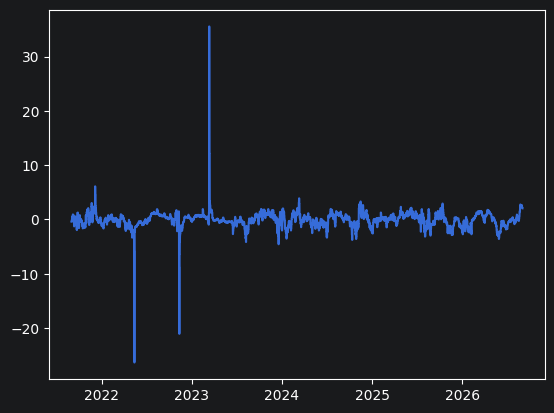

In [135]:
import matplotlib.pyplot as plt

plt.plot(df["premium_raw_coinbase_btc_1d_z90"])

In [136]:
list(df.columns)

['bar_id',
 'series_id',
 'bar_type',
 'bar_seq',
 'segment_id',
 'bar_start_us',
 'bar_end_us',
 'first_trade_ts_us',
 'last_trade_ts_us',
 'first_trade_id',
 'last_trade_id',
 'open',
 'high',
 'low',
 'close',
 'volume',
 'notional_usdt',
 'n_trades',
 'n_messages',
 'threshold_frozen',
 'complete',
 'bar_status',
 'bar_available_us',
 'decision_time_us',
 'bar_provenance',
 'bar_start',
 'bar_end',
 'bar_available',
 'decision_time',
 'ret_bars_1',
 'ret_bars_5',
 'ret_bars_20',
 'ret_5min',
 'ret_5min_ref_age_s',
 'ret_1h',
 'ret_1h_ref_age_s',
 'ret_4h',
 'ret_4h_ref_age_s',
 'ret_1d',
 'ret_1d_ref_age_s',
 'ret_7d',
 'ret_7d_ref_age_s',
 'ret_30d',
 'ret_30d_ref_age_s',
 'rv_1h',
 'rvol_1h',
 'rvol_ann_1h',
 'rv_1d',
 'rvol_1d',
 'rvol_ann_1d',
 'rv_7d',
 'rvol_7d',
 'rvol_ann_7d',
 'rv_30d',
 'rvol_30d',
 'rvol_ann_30d',
 'rv_bars_20',
 'rv_bars_100',
 'bar_duration_s',
 'trade_span_s',
 'avg_trade_size',
 'trade_intensity_per_s',
 'volume_per_s',
 'notional_per_s',
 'aggr_buy_

In [137]:
# chronological split exactly as in the source notebook -- never shuffled
dev_all, test_events = train_test_split(trades, test_size=TEST_SIZE, shuffle=False)
test_start = test_events["decision_time"].iloc[0]
test_end = test_events["exit_time"].max()

# purge: a development event whose label interval [decision_time, exit_time] reaches the test period is dropped
# (source rule `exit_time < test_start`; every development decision_time is < test_start by construction)
overlaps_test = dev_all["exit_time"] >= test_start
dev = dev_all.loc[~overlaps_test]

assert dev["decision_time"].max() < test_start <= test_events["decision_time"].min()
assert (dev["exit_time"] < test_start).all()


pd.DataFrame({
    "events": [len(dev_all), len(dev), len(test_events)],
    "first decision": [dev_all.decision_time.min(), dev.decision_time.min(), test_events.decision_time.min()],
    "last decision": [dev_all.decision_time.max(), dev.decision_time.max(), test_events.decision_time.max()],
    "last exit": [dev_all.exit_time.max(), dev.exit_time.max(), test_end],
}, index=["development (before purge)", "development (eligible)", "final test"]).assign(
    purged_overlapping_test=[0, int(overlaps_test.sum()), 0])

,events,first decision,last decision,last exit,purged_overlapping_test
development (before purge),763,2021-09-01 05:52:16.156000+00:00,2025-02-17 08:50:09.791283+00:00,2025-02-17 11:20:20.793544+00:00,0
development (eligible),763,2021-09-01 05:52:16.156000+00:00,2025-02-17 08:50:09.791283+00:00,2025-02-17 11:20:20.793544+00:00,0
final test,328,2025-02-17 14:10:21.275987+00:00,2026-08-30 16:12:40.771783+00:00,2026-08-30 22:10:04.712859+00:00,0


In [138]:
# development: DatetimeIndex = event start (decision time), values = event end (exit time) -> PurgedKFold input
dev = dev.copy()
dev.index = pd.DatetimeIndex(dev["decision_time"], name="event_start")
X_dev = dev[features]
y_dev = dev["trade_return"].gt(0).astype("int8")
t1_dev = pd.Series(pd.DatetimeIndex(dev["exit_time"]), index=dev.index, name="event_end")

# net PnL of one trade at a fixed notional. `trade_return` is already NET of the simulator's costs: costs are not subtracted again.
pnl_dev = (FIXED_NOTIONAL * dev["trade_return"]).to_numpy()
pnl_test = (FIXED_NOTIONAL * test_events["trade_return"]).to_numpy()

# the score is a sum of event PnLs: it is only meaningful as "the PnL of independent trades" if events do not overlap in time
exit_ns = pd.DatetimeIndex(dev["exit_time"]).asi8
start_ns = dev.index.asi8
n_overlapping_dev = int((start_ns[1:] <= np.maximum.accumulate(exit_ns)[:-1]).sum())
print(f"development events that start before an earlier event has exited: {n_overlapping_dev}"
      + ("" if n_overlapping_dev == 0 else "  -> the summed PnL treats overlapping events as independent, fixed-notional trades"))

X_test = test_events[features]
y_test = test_events["trade_return"].gt(0).astype("int8")

print(f"development: {len(X_dev)} events, profitable share {y_dev.mean():.3f}")
print(f"final test : {len(X_test)} events, profitable share {y_test.mean():.3f}")
all_nan = [c for c in features if X_dev[c].isna().all()]
print("\nfeatures with no value on ANY development event:", all_nan)
print("  of these, also all-NaN on the test events:", [c for c in all_nan if X_test[c].isna().all()])

development events that start before an earlier event has exited: 0
development: 763 events, profitable share 0.478
final test : 328 events, profitable share 0.488

features with no value on ANY development event: []
  of these, also all-NaN on the test events: []


Features that are entirely missing on the development events carry no information. They are part of the source notebook's feature set and the set is kept
fixed; the median imputer drops all-NaN columns (fitted per fold) and CatBoost ignores them, so the models effectively use the remaining columns.

## 2. Equity and economics function (copied unchanged from the source notebook)

In [139]:
def plot_strategy_equity(
    trades,
    model=None,
    feature_cols=None,
    threshold=0.50,
    initial_capital=10_000,
    position_size=10_000,
):
    t = trades.loc[trades["trade_status"].eq("closed")].copy()

    if t.empty:
        raise ValueError("Nu există tranzacții închise.")

    t["entry_time"] = pd.to_datetime(t["entry_time"], utc=True)
    t["exit_time"] = pd.to_datetime(t["exit_time"], utc=True)
    t = t.sort_values("exit_time", kind="stable").reset_index(drop=True)

    net_return = t["trade_return"]  # Include deja costurile simulatorului.
    pnl = net_return * position_size
    dates = [t["entry_time"].min(), *t["exit_time"].tolist()]

    selections = {
        "Strategia de bază": pd.Series(True, index=t.index),
    }

    if model is not None:
        if feature_cols is None:
            feature_cols = list(model.feature_names_in_)

        positive_class = list(model.classes_).index(1)
        p_profit = model.predict_proba(t[list(feature_cols)])[:, positive_class]

        selections[f"Strategie + meta-model (prag {threshold:.0%})"] = (
            pd.Series(p_profit, index=t.index).ge(threshold)
        )

    fig, ax = plt.subplots(figsize=(14, 6))
    summary = []

    for name, accepted in selections.items():
        # Un semnal respins are PnL zero, pe aceeași axă de timp.
        selected_pnl = pnl.where(accepted, 0.0)
        equity = initial_capital + selected_pnl.cumsum()
        accepted_returns = net_return.loc[accepted]

        ax.step(
            dates,
            [initial_capital, *equity.tolist()],
            where="post",
            linewidth=1.5,
            label=name,
        )

        summary.append({
            "Variantă": name,
            "Capital final (USD)": equity.iloc[-1],
            "PnL net (USD)": selected_pnl.sum(),
            "Tranzacții": int(accepted.sum()),
            "Semnale păstrate (%)": 100 * accepted.mean(),
            "Win rate net (%)": 100 * accepted_returns.gt(0).mean(),
            "Randament mediu net (%)": 100 * accepted_returns.mean(),
        })

    ax.axhline(
        initial_capital, color="gray", linestyle="--", label="Capital inițial"
    )
    ax.set(title="Curba capitalului la închiderea tranzacțiilor",
           xlabel="Data", ylabel="Capital (USD)")
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()

    return pd.DataFrame(summary).set_index("Variantă")

## 3. Identical `PurgedKFold` splits on the development set

The splitter is built **once**, from the eligible development events only (`samples_info_sets` = decision time → exit time), so the embargo
`floor(n_dev · pct_embargo)` refers to the development sample. The list of folds is materialised once and handed to all four models, which guarantees identical splits.

In [140]:
cv = PurgedKFold(n_splits=N_SPLITS, samples_info_sets=t1_dev, pct_embargo=PCT_EMBARGO)
print(cv)
folds = list(cv.split_with_diagnostics(X_dev))

fold_table = pd.DataFrame({
    "test_start": [f.test_start for f in folds],
    "max_test_end": [f.test_end for f in folds],
    "n_train": [len(f.train) for f in folds],
    "n_test": [len(f.test) for f in folds],
    "n_purged": [len(f.purged) for f in folds],
    "n_embargoed": [len(f.embargoed) for f in folds],
    "train_profitable_share": [y_dev.iloc[f.train].mean() for f in folds],
    "test_profitable_share": [y_dev.iloc[f.test].mean() for f in folds],
}).rename_axis("fold")
print("embargo_count =", int(np.floor(len(X_dev) * PCT_EMBARGO)), "observations")

# every observation is in exactly one test fold; each training fold has both classes; no train interval reaches a test window
seen = np.concatenate([f.test for f in folds])
assert sorted(seen) == list(range(len(X_dev)))
for f in folds:
    assert y_dev.iloc[f.train].nunique() == 2
    tr_s, tr_e = t1_dev.index[f.train], pd.DatetimeIndex(t1_dev.iloc[f.train])
    assert not ((tr_s <= f.test_end) & (tr_e >= f.test_start)).any()
fold_table

PurgedKFold(n_splits=5, pct_embargo=0.02, samples_info_sets=<763 events, 2021-09-01 05:52:16.156000+00:00 .. 2025-02-17 08:50:09.791283+00:00>)
embargo_count = 15 observations


,test_start,max_test_end,n_train,n_test,n_purged,n_embargoed,train_profitable_share,test_profitable_share
fold,,,,,,,,
0,2021-09-01 05:52:16.156000+00:00,2022-06-06 03:47:51.390000+00:00,595,153,0,15,0.485714,0.457516
1,2022-06-07 18:30:11.312000+00:00,2022-09-28 16:01:06.243000+00:00,595,153,0,15,0.482353,0.470588
2,2022-09-28 16:03:53.595000+00:00,2023-05-16 01:05:42.721000+00:00,595,153,0,15,0.477311,0.490196
3,2023-05-17 17:48:10.716000+00:00,2024-04-15 09:44:36.148000+00:00,596,152,0,15,0.478188,0.460526
4,2024-04-19 04:36:55.520000+00:00,2025-02-17 11:20:20.793544+00:00,611,152,0,0,0.469722,0.513158


## 4. The four models (fixed hyper-parameters, no search)

* **LogReg** and **CatBoost**: exactly as in the source notebook (CatBoost additionally has `allow_writing_files=False` so no `catboost_info/` directory is written; this does not change the fit).
* **RandomForest** and **GradientBoosting**: new, a-priori values, shallow / regularised for a small training sample. scikit-learn's `GradientBoostingClassifier` rejects NaN,
  so both new models get the same fold-fitted median imputer as the baseline. CatBoost handles missing values natively and has no preprocessing step.

These objects are *templates*: every fold fits a `sklearn.base.clone` of them, and the templates themselves are never fitted.

In [141]:
models = {
    "LogReg": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(penalty="l2", C=1.0, max_iter=1000),
    ),
    "CatBoost": CatBoostClassifier(
        iterations=150,
        depth=2,
        learning_rate=0.03,
        l2_leaf_reg=10,
        loss_function="Logloss",
        random_seed=SEED,
        verbose=False,
        allow_writing_files=False,
    ),
    "RandomForest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(n_estimators=300, max_depth=3, min_samples_leaf=10, random_state=SEED, n_jobs=1),
    ),
    "GradientBoosting": make_pipeline(
        SimpleImputer(strategy="median"),
        GradientBoostingClassifier(n_estimators=150, learning_rate=0.03, max_depth=2, random_state=SEED),
    ),
}
MODEL_ORDER = {name: i for i, name in enumerate(models)}     # used only as the last tie-break key
list(models)

['LogReg', 'CatBoost', 'RandomForest', 'GradientBoosting']

## 5. Out-of-fold probabilities of the profitable class

For each fold: clone the template → fit on the fold's training rows only (so imputer medians and scaler statistics come from training rows) → predict the held-out fold.
The result is one aligned OOF probability per development event (every event is held out exactly once). `DummyClassifier("prior")` runs through the same loop as a *reference only* (the log loss
of knowing nothing but the training prevalence); it is not a candidate.

In [142]:
def oof_proba(template, X, y, folds):
    oof = np.full(len(X), np.nan)
    fitted = []
    for fold in folds:
        est = clone(template)                                   # fresh object per fold
        est.fit(X.iloc[fold.train], y.iloc[fold.train])         # preprocessing is fitted here, on training rows only
        pos = list(est.classes_).index(1)                       # column of the profitable class
        oof[fold.test] = est.predict_proba(X.iloc[fold.test])[:, pos]
        fitted.append(est)
    assert not np.isnan(oof).any(), "OOF probabilities must cover every development event"
    return oof, fitted

oof, fold_estimators = {}, {}
for name, template in models.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        oof[name], fold_estimators[name] = oof_proba(template, X_dev, y_dev, folds)
oof_prior, _ = oof_proba(DummyClassifier(strategy="prior"), X_dev, y_dev, folds)

oof_df = pd.DataFrame(oof, index=X_dev.index)
oof_df.describe().T[["min", "25%", "50%", "75%", "max"]].round(3)

,min,25%,50%,75%,max
LogReg,0.145,0.437,0.490,0.537,0.809
CatBoost,0.361,0.465,0.485,0.513,0.574
RandomForest,0.320,0.461,0.484,0.514,0.574
GradientBoosting,0.145,0.442,0.489,0.548,0.727


### Leakage checks

* Templates are untouched (cloning really happened): none of them is fitted.
* For the pipelines, each fold's fitted imputer medians (and the scaler mean of the baseline) equal the statistics of **that fold's training rows**, and differ from the full development sample's.

In [143]:
from sklearn.exceptions import NotFittedError
from sklearn.utils.validation import check_is_fitted

for name, template in models.items():
    if name == "CatBoost":
        assert not template.is_fitted()
    else:
        try:
            check_is_fitted(template[-1]); raise AssertionError(f"{name} template was fitted")
        except NotFittedError:
            pass
        try:
            check_is_fitted(template[0]); raise AssertionError(f"{name} imputer template was fitted")
        except NotFittedError:
            pass

rows = []
for name in ("LogReg", "RandomForest", "GradientBoosting"):
    for k, (est, fold) in enumerate(zip(fold_estimators[name], folds)):
        imp = est[0]
        Xtr = X_dev.iloc[fold.train]
        has_values = ~Xtr.isna().all().to_numpy()
        kept = Xtr.columns[has_values]
        stats = imp.statistics_                                  # NaN entries mark columns that were all-NaN in training
        assert np.isnan(stats[~has_values]).all()
        assert np.allclose(stats[has_values], Xtr[kept].median().to_numpy())
        full_med = X_dev[kept].median().to_numpy()
        differs = not np.allclose(stats[has_values], full_med)
        if name == "LogReg":
            assert np.allclose(est[1].mean_, Xtr[kept].fillna(Xtr[kept].median()).mean().to_numpy())
            assert est[1].n_samples_seen_ == len(fold.train)
        rows.append({"model": name, "fold": k, "n_train": len(fold.train), "kept_features": len(kept),
                     "imputer_medians == fold-train medians": True, "differs from full-dev medians": differs})
pd.DataFrame(rows).groupby("model").agg({"n_train": "min", "kept_features": "first",
                                          "imputer_medians == fold-train medians": "all",
                                          "differs from full-dev medians": "any"})

,n_train,kept_features,imputer_medians == fold-train medians,differs from full-dev medians
model,,,,
GradientBoosting,595,13,True,True
LogReg,595,13,True,True
RandomForest,595,13,True,True


## 6. Threshold grid: fixed-notional OOF net PnL, with classification diagnostics

A development event is *accepted* when `p(profitable) >= threshold` (the same `>=` rule as `plot_strategy_equity`). For every model × threshold the pooled OOF predictions
(all development events, each predicted by the model that did not see it) give

* **`oof_net_pnl`** — the selection score: `sum(accepted * FIXED_NOTIONAL * trade_return)` over all development events, plus the same sum **per fold** (the per-fold values add up to the pooled score);
* accepted trade count and acceptance rate;
* diagnostics only: precision, recall and F1 of the profitable class, and the pooled OOF log loss (threshold-independent, repeated on each row of a model).

Two **model-free alternatives** use the same score: *accept-all* (every event, i.e. the unfiltered strategy) and *reject-all* (no event, score 0).

In [144]:
y_dev_arr = y_dev.to_numpy()
fold_of = np.empty(len(X_dev), dtype=int)
for k, fold in enumerate(folds):
    fold_of[fold.test] = k

def clf_metrics(y, accepted):
    y, accepted = np.asarray(y), np.asarray(accepted)
    return {
        "n_accepted": int(accepted.sum()),
        "acceptance_rate": float(accepted.mean()),
        "precision": precision_score(y, accepted, zero_division=0),
        "recall": recall_score(y, accepted, zero_division=0),
        "f1": f1_score(y, accepted, zero_division=0),
    }

def pnl_score(accepted, pnl):
    """Fixed-notional event PnL: rejected events contribute exactly zero."""
    return float((np.asarray(accepted) * np.asarray(pnl)).sum())

def pnl_by_fold(accepted):
    a = np.asarray(accepted)
    return np.array([pnl_score(a[fold.test], pnl_dev[fold.test]) for fold in folds])

rows, fold_rows = [], []
for name, p in oof.items():
    ll = log_loss(y_dev_arr, p, labels=[0, 1])
    for thr in THRESHOLDS:
        acc = p >= thr
        per_fold = pnl_by_fold(acc)
        assert np.isclose(per_fold.sum(), pnl_score(acc, pnl_dev)), "per-fold PnL must add up to the pooled score"
        rows.append({"model": name, "kind": "model", "threshold": thr, "oof_net_pnl": pnl_score(acc, pnl_dev),
                     "folds_positive": int((per_fold > 0).sum()), **clf_metrics(y_dev_arr, acc), "log_loss": ll})
        fold_rows += [{"model": name, "threshold": thr, "fold": k, "pnl": v,
                       "n_accepted": int(acc[folds[k].test].sum())} for k, v in enumerate(per_fold)]
grid = pd.DataFrame(rows)
fold_pnl = pd.DataFrame(fold_rows)

free_rows = []
for label, acc in [("accept-all", np.ones(len(y_dev_arr), dtype=bool)), ("reject-all", np.zeros(len(y_dev_arr), dtype=bool))]:
    per_fold = pnl_by_fold(acc)
    free_rows.append({"model": label, "kind": "model-free", "threshold": np.nan, "oof_net_pnl": pnl_score(acc, pnl_dev),
                      "folds_positive": int((per_fold > 0).sum()), **clf_metrics(y_dev_arr, acc), "log_loss": np.nan})
    fold_rows_free = [{"model": label, "threshold": np.nan, "fold": k, "pnl": v, "n_accepted": int(acc[folds[k].test].sum())}
                      for k, v in enumerate(per_fold)]
    fold_pnl = pd.concat([fold_pnl, pd.DataFrame(fold_rows_free)], ignore_index=True)
free = pd.DataFrame(free_rows).set_index("model", drop=False)
ACCEPT_ALL_PNL, ACCEPT_ALL_F1 = free.loc["accept-all", "oof_net_pnl"], free.loc["accept-all", "f1"]

prior_ll = log_loss(y_dev_arr, oof_prior, labels=[0, 1])
print(f"accept-all: OOF fixed-notional net PnL {ACCEPT_ALL_PNL:,.2f} USD over {len(y_dev_arr)} events "
      f"(profitable share {y_dev_arr.mean():.4f}, F1 {ACCEPT_ALL_F1:.4f}); reject-all: 0.00 USD")
print(f"prior-only reference log loss (fold-train prevalence) = {prior_ll:.4f}")

model_level = pd.DataFrame({
    "OOF log loss": {n: log_loss(y_dev_arr, p, labels=[0, 1]) for n, p in oof.items()},
    "OOF ROC-AUC": {n: roc_auc_score(y_dev_arr, p) for n, p in oof.items()},
}).rename_axis("model")
model_level.loc["prior-only (reference)"] = [prior_ll, 0.5]
model_level.round(4)

accept-all: OOF fixed-notional net PnL -4,762.09 USD over 763 events (profitable share 0.4784, F1 0.6472); reject-all: 0.00 USD
prior-only reference log loss (fold-train prevalence) = 0.6927


,OOF log loss,OOF ROC-AUC
model,,
LogReg,0.7038,0.5100
CatBoost,0.6961,0.4887
RandomForest,0.6970,0.4880
GradientBoosting,0.7077,0.4907
prior-only (reference),0.6927,0.5000


### Selection rule (deterministic)

Candidates: every model × threshold pair, plus *accept-all* and *reject-all*. Choose by this lexicographic key, first criterion first:

1. **highest** pooled OOF fixed-notional net PnL (compared after rounding to 1e-6 USD, so float noise cannot decide);
2. **fewest** accepted trades (equal PnL with less exposure; this also ranks *reject-all* before anything that trades for the same PnL);
3. model-free alternatives before model × threshold pairs (the simpler rule);
4. among model pairs: **lowest** pooled OOF log loss, then threshold **closest to 0.5**, then **lower** threshold, then earlier position in the model list `LogReg, CatBoost, RandomForest, GradientBoosting`.

Nothing in the rule involves the final test, and F1, precision, recall and log loss never override the PnL criterion (log loss only enters as a late tie-break).

If a model-free alternative wins, *no model is selected*; the best model × threshold pair (same key, restricted to model pairs) is then used only as the **reference model** that is refitted for the threshold-0.5 comparison on the final test.

In [145]:
cand = pd.concat([grid, free.reset_index(drop=True)], ignore_index=True)
cand_ranked = cand.assign(
    _pnl=cand["oof_net_pnl"].round(6),
    _is_model=(cand["kind"] == "model").astype(int),
    _ll=cand["log_loss"].fillna(0.0),
    _dist=(cand["threshold"] - 0.5).abs().round(10).fillna(0.0),
    _thr=cand["threshold"].fillna(0.0),
    _order=cand["model"].map(MODEL_ORDER).fillna(-1),
).sort_values(
    ["_pnl", "n_accepted", "_is_model", "_ll", "_dist", "_thr", "_order"],
    ascending=[False, True, True, True, True, True, True],
    kind="stable",
).reset_index(drop=True)

best = cand_ranked.iloc[0]
best_pair = cand_ranked[cand_ranked["kind"] == "model"].iloc[0]       # best model x threshold pair, same key
SELECTED_KIND = best["kind"]                                          # "model" | "model-free"
REF_MODEL = best_pair["model"]                                        # model refitted for the final-test comparison
SEL_MODEL = best["model"] if SELECTED_KIND == "model" else None
SEL_THR = float(best["threshold"]) if SELECTED_KIND == "model" else None
n_tied = int((cand_ranked["_pnl"] == best["_pnl"]).sum())

if SELECTED_KIND == "model":
    print(f"selected: {SEL_MODEL} @ threshold {SEL_THR:.2f}   (pooled OOF net PnL {best['oof_net_pnl']:,.2f} USD, "
          f"{int(best['n_accepted'])} of {len(y_dev_arr)} events accepted; {n_tied} candidate(s) share this PnL)")
else:
    print(f"selected: {best['model']}  (pooled OOF net PnL {best['oof_net_pnl']:,.2f} USD) -- no model x threshold pair beat it on development data")
    if best["model"] == "reject-all":
        print("  -> REJECT-ALL WINS: no filtered or unfiltered rule had positive OOF net PnL; no trades are forced.")
    print(f"  best model pair (reference only, NOT selected): {REF_MODEL} @ {best_pair['threshold']:.2f} "
          f"with OOF net PnL {best_pair['oof_net_pnl']:,.2f} USD")

cols = ["model", "threshold", "oof_net_pnl", "n_accepted", "acceptance_rate", "folds_positive",
        "f1", "precision", "recall", "log_loss"]
dev_table = pd.concat([cand_ranked[cand_ranked["kind"] == "model"][cols].head(10), free[cols]], ignore_index=True)
dev_table.round(4)

selected: CatBoost @ threshold 0.55   (pooled OOF net PnL 316.72 USD, 24 of 763 events accepted; 1 candidate(s) share this PnL)


,model,threshold,oof_net_pnl,n_accepted,acceptance_rate,folds_positive,f1,precision,recall,log_loss
0,CatBoost,0.55,316.7231,24,0.0315,3,0.0668,0.5417,0.0356,0.6961
1,RandomForest,0.55,254.5503,38,0.0498,2,0.0993,0.5263,0.0548,0.6970
2,CatBoost,0.60,0.0000,0,0.0000,0,0.0000,0.0000,0.0000,0.6961
3,CatBoost,0.65,0.0000,0,0.0000,0,0.0000,0.0000,0.0000,0.6961
4,CatBoost,0.70,0.0000,0,0.0000,0,0.0000,0.0000,0.0000,0.6961
5,RandomForest,0.60,0.0000,0,0.0000,0,0.0000,0.0000,0.0000,0.6970
6,RandomForest,0.65,0.0000,0,0.0000,0,0.0000,0.0000,0.0000,0.6970
7,RandomForest,0.70,0.0000,0,0.0000,0,0.0000,0.0000,0.0000,0.6970
8,GradientBoosting,0.70,-38.7700,4,0.0052,1,0.0054,0.2500,0.0027,0.7077
9,GradientBoosting,0.65,-477.0823,19,0.0249,2,0.0417,0.4211,0.0219,0.7077


### OOF net PnL by threshold, by fold, with accepted counts and acceptance rates

Everything below is a development / selection statistic (fixed-notional event PnL in USD), not an independent estimate of how the selected rule will perform.

In [146]:
def with_free(pivot, key, fmt_all=None):
    """append the model-free rows (same value for every model column)"""
    out = pivot.copy()
    out.loc["accept-all"] = free.loc["accept-all", key]
    out.loc["reject-all"] = free.loc["reject-all", key]
    return out

order = list(models)
print("Pooled OOF fixed-notional net PnL (USD) by threshold")
display(with_free(grid.pivot(index="threshold", columns="model", values="oof_net_pnl")[order], "oof_net_pnl").round(2))

print("Accepted trade count (of %d development events)" % len(y_dev_arr))
display(with_free(grid.pivot(index="threshold", columns="model", values="n_accepted")[order], "n_accepted").astype(int))

print("Acceptance rate")
display(with_free(grid.pivot(index="threshold", columns="model", values="acceptance_rate")[order], "acceptance_rate").round(3))

print("Number of folds with positive OOF net PnL (of %d)" % N_SPLITS)
display(with_free(grid.pivot(index="threshold", columns="model", values="folds_positive")[order], "folds_positive").astype(int))

Pooled OOF fixed-notional net PnL (USD) by threshold


model,LogReg,CatBoost,RandomForest,GradientBoosting
threshold,,,,
0.3,-3872.06,-4762.09,-4762.09,-3956.37
0.35,-3224.68,-4762.09,-4637.57,-3248.09
0.4,-3526.76,-4753.16,-5090.15,-3415.24
0.45,-2428.24,-3585.42,-4735.48,-3513.00
0.5,-4280.76,-3633.86,-3192.39,-3348.54
0.55,-731.69,316.72,254.55,-3262.72
0.6,-2301.81,0.00,0.00,-531.84
0.65,-1538.56,0.00,0.00,-477.08
0.7,-1112.08,0.00,0.00,-38.77


Accepted trade count (of 763 development events)


model,LogReg,CatBoost,RandomForest,GradientBoosting
threshold,,,,
0.3,749,763,763,738
0.35,725,763,760,716
0.4,654,756,744,671
0.45,530,673,641,541
0.5,342,270,264,339
0.55,155,24,38,183
0.6,48,0,0,58
0.65,12,0,0,19
0.7,4,0,0,4


Acceptance rate


model,LogReg,CatBoost,RandomForest,GradientBoosting
threshold,,,,
0.3,0.982,1.000,1.000,0.967
0.35,0.950,1.000,0.996,0.938
0.4,0.857,0.991,0.975,0.879
0.45,0.695,0.882,0.840,0.709
0.5,0.448,0.354,0.346,0.444
0.55,0.203,0.031,0.050,0.240
0.6,0.063,0.000,0.000,0.076
0.65,0.016,0.000,0.000,0.025
0.7,0.005,0.000,0.000,0.005


Number of folds with positive OOF net PnL (of 5)


model,LogReg,CatBoost,RandomForest,GradientBoosting
threshold,,,,
0.3,1,1,1,1
0.35,1,1,1,1
0.4,1,1,1,1
0.45,1,1,1,2
0.5,0,3,1,1
0.55,2,3,2,1
0.6,1,0,0,3
0.65,1,0,0,2
0.7,1,0,0,1


In [147]:
print("OOF fixed-notional net PnL (USD) by fold: rows = (model, fold), columns = threshold")
fp = fold_pnl[fold_pnl["model"].isin(order)].pivot_table(index=["model", "fold"], columns="threshold", values="pnl", sort=False)
fp = fp.loc[order]
display(fp.round(2))

print("Model-free alternatives by fold (accepted trades and PnL)")
ff = fold_pnl[~fold_pnl["model"].isin(order)].pivot_table(index="fold", columns="model", values=["pnl", "n_accepted"])
ff["n_test"] = [len(f.test) for f in folds]
display(ff.round(2))

print("Selected rule by fold")
if SELECTED_KIND == "model":
    sel = fold_pnl[(fold_pnl["model"] == SEL_MODEL) & np.isclose(fold_pnl["threshold"], SEL_THR)].set_index("fold")
else:
    sel = fold_pnl[fold_pnl["model"] == best["model"]].set_index("fold")
sel = sel[["n_accepted", "pnl"]].rename(columns={"pnl": "selected_rule_pnl"})
sel["accept_all_pnl"] = fold_pnl[fold_pnl["model"] == "accept-all"].set_index("fold")["pnl"]
sel["n_test"] = [len(f.test) for f in folds]
display(sel.round(2))

OOF fixed-notional net PnL (USD) by fold: rows = (model, fold), columns = threshold


threshold                 0.30     0.35     0.40     0.45     0.50     0.55     0.60     0.65    0.70
model            fold                                                                                
LogReg           0    -1375.77 -1046.85 -1020.73 -1641.66 -1076.43   -10.02 -1006.60  -484.11 -359.70
                 1    -2584.66 -2432.12 -2304.79 -1730.50 -1868.66 -1146.49 -1444.34 -1052.77 -760.59
                 2     1906.39  2080.04  1549.29  2106.44   -33.03    48.16  -130.62     0.00    0.00
                 3    -1217.29  -802.00  -417.75  -309.99  -304.47  -289.23   325.52    44.09    0.00
                 4     -600.73 -1023.75 -1332.79  -852.54  -998.16   665.88   -45.77   -45.77    8.20
CatBoost         0    -1659.15 -1659.15 -1659.15 -1317.99 -1352.52  -283.10     0.00     0.00    0.00
                 1    -2701.26 -2701.26 -2576.74 -2834.96 -2971.69   343.06     0.00     0.00    0.00
                 2     1862.31  1862.31  1862.31  1735.97   411.79   135.74     0.00     0.00    0.00
                 3    -1372.42 -1372.42 -1361.84 -1021.97    89.66   121.03     0.00     0.00    0.00
                 4     -891.57  -891.57 -1017.74  -146.47   188.90     0.00     0.00     0.00    0.00
RandomForest     0    -1659.15 -1659.15 -1491.65 -1402.84  -802.66   -22.93     0.00     0.00    0.00
                 1    -2701.26 -2576.74 -3014.59 -2984.09 -1792.67   233.60     0.00     0.00    0.00
                 2     1862.31  1862.31  1863.34  1218.76   508.61    -8.06     0.00     0.00    0.00
                 3    -1372.42 -1372.42 -1210.58 -1149.23  -212.14    51.94     0.00     0.00    0.00
                 4     -891.57  -891.57 -1236.66  -418.09  -893.52     0.00     0.00     0.00    0.00
GradientBoosting 0    -1193.89  -983.88   -80.78    24.25  -633.49 -1774.25  -214.10  -544.47 -114.73
                 1    -2948.74 -3137.22 -3743.39 -3567.91 -2065.36 -1591.55  -740.55    81.40    0.00
                 2     2404.87  2476.43  2271.27  1274.02   253.73   201.54   143.92     0.00    0.00
                 3    -1268.68  -947.78 -1032.45  -686.08  -613.28   -48.17    72.61   166.50   75.96
                 4     -949.94  -655.64  -829.89  -557.27  -290.15   -50.29   206.28  -180.52    0.00

Model-free alternatives by fold (accepted trades and PnL)


n_accepted                   pnl            n_test
model accept-all reject-all accept-all reject-all       
fold                                                    
0          153.0        0.0   -1659.15        0.0    153
1          153.0        0.0   -2701.26        0.0    153
2          153.0        0.0    1862.31        0.0    153
3          152.0        0.0   -1372.42        0.0    152
4          152.0        0.0    -891.57        0.0    152

Selected rule by fold


,n_accepted,selected_rule_pnl,accept_all_pnl,n_test
fold,,,,
0,12,-283.10,-1659.15,153
1,10,343.06,-2701.26,153
2,1,135.74,1862.31,153
3,1,121.03,-1372.42,152
4,0,0.00,-891.57,152


### Full development grid with diagnostics

In [148]:
display(grid[cols].round(4).set_index(["model", "threshold"]))
print("Diagnostics only (F1 / precision / recall / log loss): they did not enter the selection, except log loss as a late tie-break.")
pivot_f1 = grid.pivot(index="threshold", columns="model", values="f1")[order]
pivot_f1.loc["accept-all"] = ACCEPT_ALL_F1
display(pivot_f1.round(4))

oof_net_pnl  n_accepted  acceptance_rate  folds_positive      f1  precision  recall  log_loss
model            threshold                                                                                               
LogReg           0.30        -3872.0591         749           0.9817               1  0.6481     0.4820  0.9890    0.7038
                 0.35        -3224.6763         725           0.9502               1  0.6477     0.4869  0.9671    0.7038
                 0.40        -3526.7636         654           0.8571               1  0.6222     0.4847  0.8685    0.7038
                 0.45        -2428.2438         530           0.6946               1  0.5810     0.4906  0.7123    0.7038
                 0.50        -4280.7630         342           0.4482               0  0.4639     0.4795  0.4493    0.7038
                 0.55         -731.6877         155           0.2031               2  0.3038     0.5097  0.2164    0.7038
                 0.60        -2301.8109          48           0.0629               1  0.0872     0.3750  0.0493    0.7038
                 0.65        -1538.5621          12           0.0157               1  0.0159     0.2500  0.0082    0.7038
                 0.70        -1112.0807           4           0.0052               1  0.0054     0.2500  0.0027    0.7038
CatBoost         0.30        -4762.0889         763           1.0000               1  0.6472     0.4784  1.0000    0.6961
                 0.35        -4762.0889         763           1.0000               1  0.6472     0.4784  1.0000    0.6961
                 0.40        -4753.1640         756           0.9908               1  0.6423     0.4762  0.9863    0.6961
                 0.45        -3585.4155         673           0.8820               1  0.6224     0.4799  0.8849    0.6961
                 0.50        -3633.8559         270           0.3539               3  0.3906     0.4593  0.3397    0.6961
                 0.55          316.7231          24           0.0315               3  0.0668     0.5417  0.0356    0.6961
                 0.60            0.0000           0           0.0000               0  0.0000     0.0000  0.0000    0.6961
                 0.65            0.0000           0           0.0000               0  0.0000     0.0000  0.0000    0.6961
                 0.70            0.0000           0           0.0000               0  0.0000     0.0000  0.0000    0.6961
RandomForest     0.30        -4762.0889         763           1.0000               1  0.6472     0.4784  1.0000    0.6970
                 0.35        -4637.5708         760           0.9961               1  0.6453     0.4776  0.9945    0.6970
                 0.40        -5090.1453         744           0.9751               1  0.6402     0.4772  0.9726    0.6970
                 0.45        -4735.4805         641           0.8401               1  0.6123     0.4805  0.8438    0.6970
                 0.50        -3192.3879         264           0.3460               1  0.3816     0.4545  0.3288    0.6970
                 0.55          254.5503          38           0.0498               2  0.0993     0.5263  0.0548    0.6970
                 0.60            0.0000           0           0.0000               0  0.0000     0.0000  0.0000    0.6970
                 0.65            0.0000           0           0.0000               0  0.0000     0.0000  0.0000    0.6970
                 0.70            0.0000           0           0.0000               0  0.0000     0.0000  0.0000    0.6970
GradientBoosting 0.30        -3956.3681         738           0.9672               1  0.6473     0.4837  0.9781    0.7077
                 0.35        -3248.0924         716           0.9384               1  0.6420     0.4846  0.9507    0.7077
                 0.40        -3415.2405         671           0.8794               1  0.6274     0.4844  0.8904    0.7077
                 0.45        -3512.9957         541           0.7090               2  0.5740     0.4806  0.7123    0.7077
  

Diagnostics only (F1 / precision / recall / log loss): they did not enter the selection, except log loss as a late tie-break.


model,LogReg,CatBoost,RandomForest,GradientBoosting
threshold,,,,
0.3,0.6481,0.6472,0.6472,0.6473
0.35,0.6477,0.6472,0.6453,0.6420
0.4,0.6222,0.6423,0.6402,0.6274
0.45,0.5810,0.6224,0.6123,0.5740
0.5,0.4639,0.3906,0.3816,0.4489
0.55,0.3038,0.0668,0.0993,0.2920
0.6,0.0872,0.0000,0.0000,0.1277
0.65,0.0159,0.0000,0.0000,0.0417
0.7,0.0054,0.0000,0.0000,0.0054


## 7. Threshold versus pooled OOF net PnL

Left: pooled OOF fixed-notional net PnL per model; the dashed grey line is accept-all (the unfiltered strategy), the horizontal baseline at zero is reject-all, and the ring marks the selected pair (no ring when a model-free
alternative is selected). Right: the acceptance rate on the same threshold axis, which shows how much of each PnL value comes from how many trades are still taken. This is event PnL at a fixed notional, not a portfolio return.

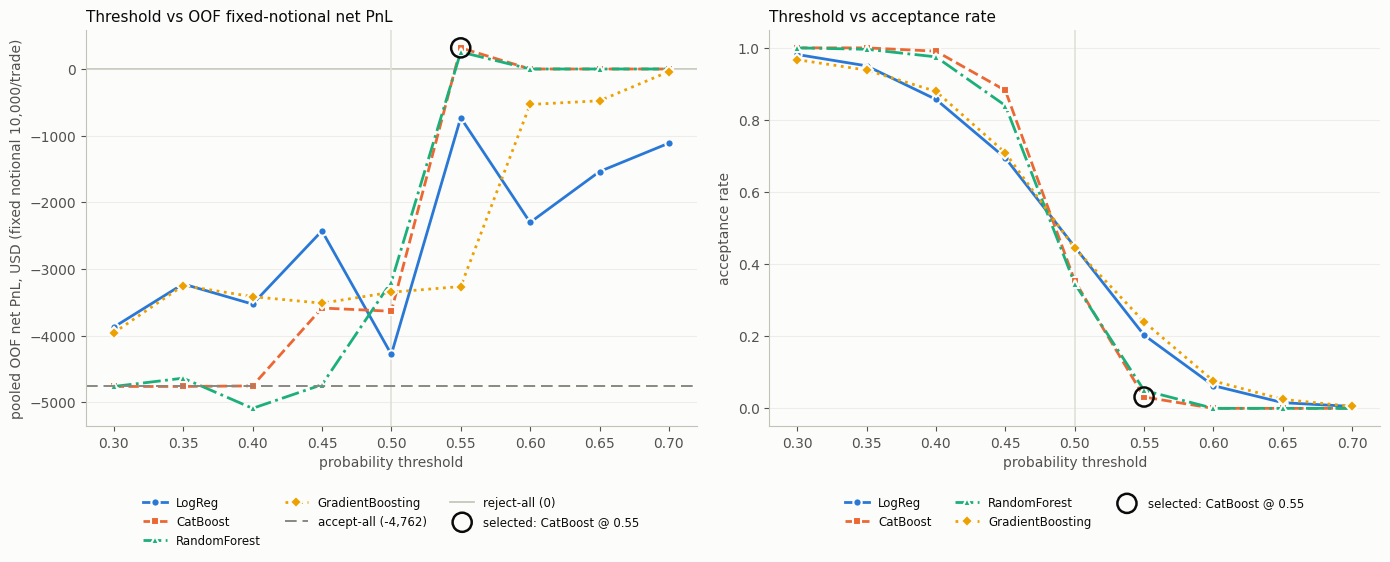

In [149]:
SERIES = {  # categorical slots 1-4 in fixed order, with a second encoding (marker + dash) so identity is not colour-alone
    "LogReg":           dict(color="#2a78d6", marker="o", ls="-"),
    "CatBoost":         dict(color="#eb6834", marker="s", ls="--"),
    "RandomForest":     dict(color="#1baf7a", marker="^", ls="-."),
    "GradientBoosting": dict(color="#eda100", marker="D", ls=":"),
}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"

def style_axes(ax, xlabel, ylabel, title):
    ax.set_facecolor("#fcfcfb")
    ax.set_xticks(THRESHOLDS)
    ax.set_xlabel(xlabel, color=MUTED); ax.set_ylabel(ylabel, color=MUTED)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.grid(axis="y", color=GRID, lw=0.8); ax.tick_params(colors=MUTED)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    for s in ("left", "bottom"): ax.spines[s].set_color("#c3c2b7")

def plot_threshold_curves(panels):
    fig, axes = plt.subplots(1, len(panels), figsize=(7 * len(panels), 5.8), facecolor="#fcfcfb")
    axes = np.atleast_1d(axes)
    for ax, (metric, ylabel, title, ref) in zip(axes, panels):
        for name, style in SERIES.items():
            g = grid[grid["model"] == name]
            ax.plot(g["threshold"], g[metric], lw=2, ms=6, markeredgecolor="#fcfcfb", markeredgewidth=1.5, label=name, **style)
        if ref is not None:
            ax.axhline(ref[0], color="#898781", lw=1.4, ls=(0, (6, 3)), label=ref[1])
        if metric == "oof_net_pnl":
            ax.axhline(0.0, color="#c3c2b7", lw=1.2, zorder=0, label="reject-all (0)")
        ax.axvline(0.5, color=GRID, lw=1.2, zorder=0)
        if SELECTED_KIND == "model":
            ax.scatter([SEL_THR], [best[metric]], s=190, facecolors="none", edgecolors=INK, linewidths=1.8, zorder=5,
                       label=f"selected: {SEL_MODEL} @ {SEL_THR:.2f}")
        style_axes(ax, "probability threshold", ylabel, title)
        ax.legend(frameon=False, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, labelcolor=INK)
    fig.tight_layout(); plt.show()

plot_threshold_curves([
    ("oof_net_pnl", f"pooled OOF net PnL, USD (fixed notional {FIXED_NOTIONAL:,}/trade)", "Threshold vs OOF fixed-notional net PnL",
     (ACCEPT_ALL_PNL, f"accept-all ({ACCEPT_ALL_PNL:,.0f})")),
    ("acceptance_rate", "acceptance rate", "Threshold vs acceptance rate", None),
])
if SELECTED_KIND == "model-free":
    print(f"Selected rule is model-free ({best['model']}): no model x threshold pair is marked.")

### Diagnostic: threshold versus pooled OOF F1

F1 of the profitable class did **not** drive the selection; it is shown for context. A high F1 (for example by accepting almost everything when the profitable share is near one half) does not imply a high PnL, and the reverse.

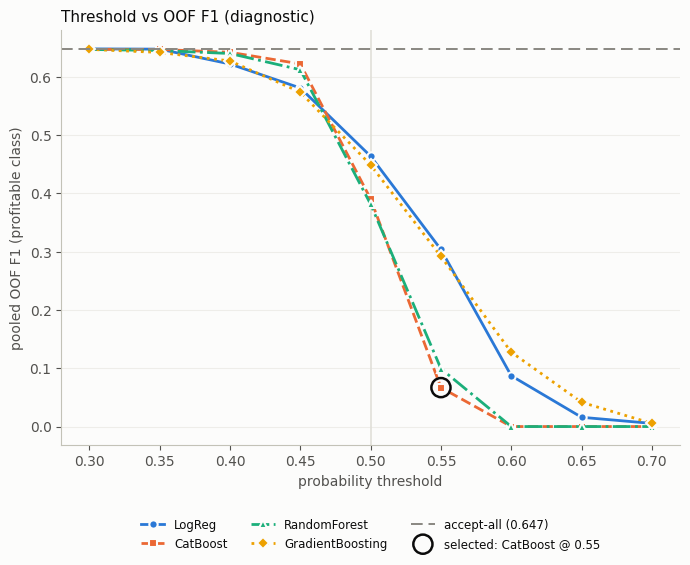

In [150]:
plot_threshold_curves([("f1", "pooled OOF F1 (profitable class)", "Threshold vs OOF F1 (diagnostic)",
                        (ACCEPT_ALL_F1, f"accept-all ({ACCEPT_ALL_F1:.3f})"))])

## 8. Final test — fitted once, threshold frozen

The model is cloned from its template and refitted on **all** eligible development events (`X_dev`, `y_dev`); its threshold from the development selection is frozen. The
final test is then scored for these rules:

1. **Unfiltered primary strategy** — every test signal is traded;
2. **the model at threshold 0.5** — the selected model, or, when a model-free alternative won, the reference model (best model pair on development);
3. **the selected rule** — the selected model at its selected threshold, or *accept-all* / *reject-all* when one of those won (reject-all trades nothing);
4. only when a model-free alternative won: the reference model at its best development threshold, listed as **reference, not selected**.

Economics come from the unchanged `plot_strategy_equity` (net `trade_return` that already contains the simulator's fees, `FIXED_NOTIONAL` per trade, rejected signals contribute zero PnL, no compounding). Its net PnL is the
same fixed-notional event PnL used for selection; it is a sum of event PnLs on one time axis, not a capital-constrained portfolio return. If two rules coincide (for example selected threshold 0.5), their rows are identical.

In [151]:
final_model = clone(models[REF_MODEL])
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    final_model.fit(X_dev, y_dev)                      # all eligible development observations, nothing from the test set
pos = list(final_model.classes_).index(1)
p_test = final_model.predict_proba(X_test)[:, pos]

n_test_events = len(y_test)
# label -> (accepted mask, threshold handed to plot_strategy_equity; None = unfiltered baseline row)
rules = {
    "Unfiltered primary strategy": (np.ones(n_test_events, dtype=bool), None),
    f"{REF_MODEL} @ 0.50": (p_test >= 0.5, 0.5),
}
if SELECTED_KIND == "model":
    rules[f"{SEL_MODEL} @ {SEL_THR:.2f} (selected)"] = (p_test >= SEL_THR, SEL_THR)
elif best["model"] == "accept-all":
    rules["accept-all (selected)"] = (np.ones(n_test_events, dtype=bool), None)
else:
    rules["reject-all (selected)"] = (np.zeros(n_test_events, dtype=bool), np.inf)    # threshold above any probability: nothing accepted
if SELECTED_KIND == "model-free":
    t_ref = float(best_pair["threshold"])
    rules[f"{REF_MODEL} @ {t_ref:.2f} (best model pair on dev: reference, not selected)"] = (p_test >= t_ref, t_ref)

test_clf = pd.DataFrame({k: clf_metrics(y_test, m) for k, (m, _) in rules.items()}).T
test_clf["accuracy"] = [accuracy_score(y_test, m) for m, _ in rules.values()]
test_clf["n_accepted"] = test_clf["n_accepted"].astype(int)
print(f"reference/selected model: {REF_MODEL};  test profitable share (base rate) = {y_test.mean():.4f};  threshold-independent: "
      f"ROC-AUC {roc_auc_score(y_test, p_test):.4f}, log loss {log_loss(y_test, p_test, labels=[0, 1]):.4f}")
test_clf.round(4)

reference/selected model: CatBoost;  test profitable share (base rate) = 0.4878;  threshold-independent: ROC-AUC 0.5628, log loss 0.6891


,n_accepted,acceptance_rate,precision,recall,f1,accuracy
Unfiltered primary strategy,328,1.0000,0.4878,1.000,0.6557,0.4878
CatBoost @ 0.50,91,0.2774,0.5714,0.325,0.4143,0.5518
CatBoost @ 0.55 (selected),1,0.0030,0.0000,0.000,0.0000,0.5091


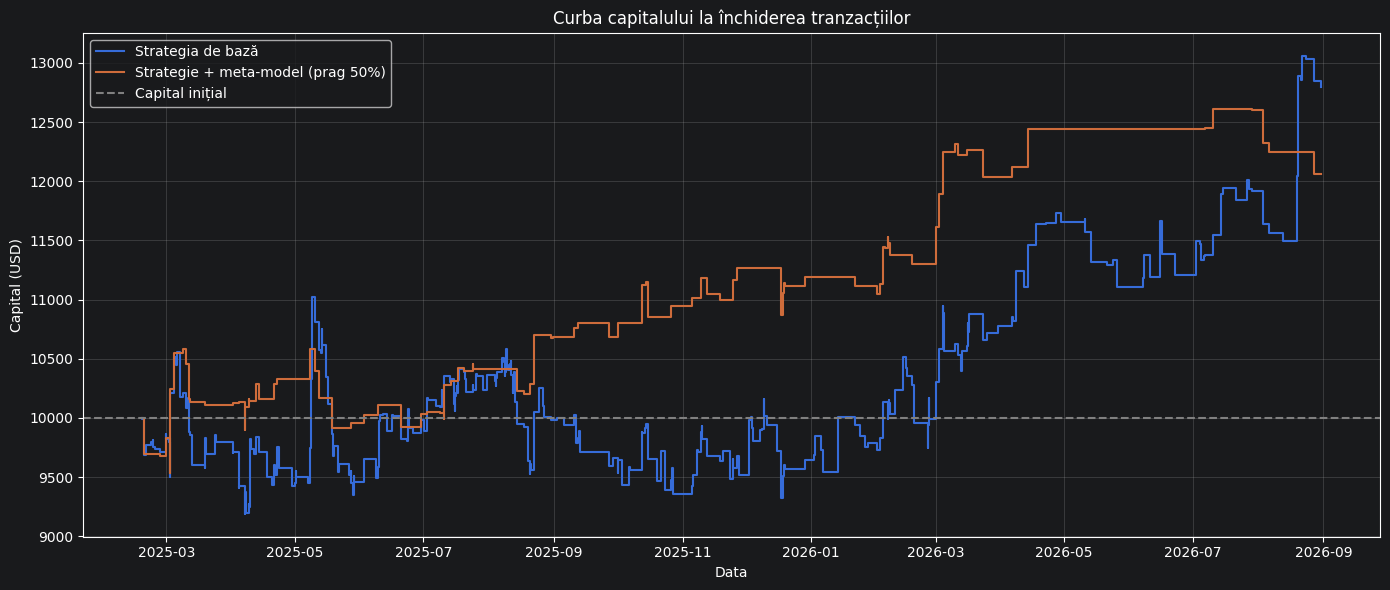

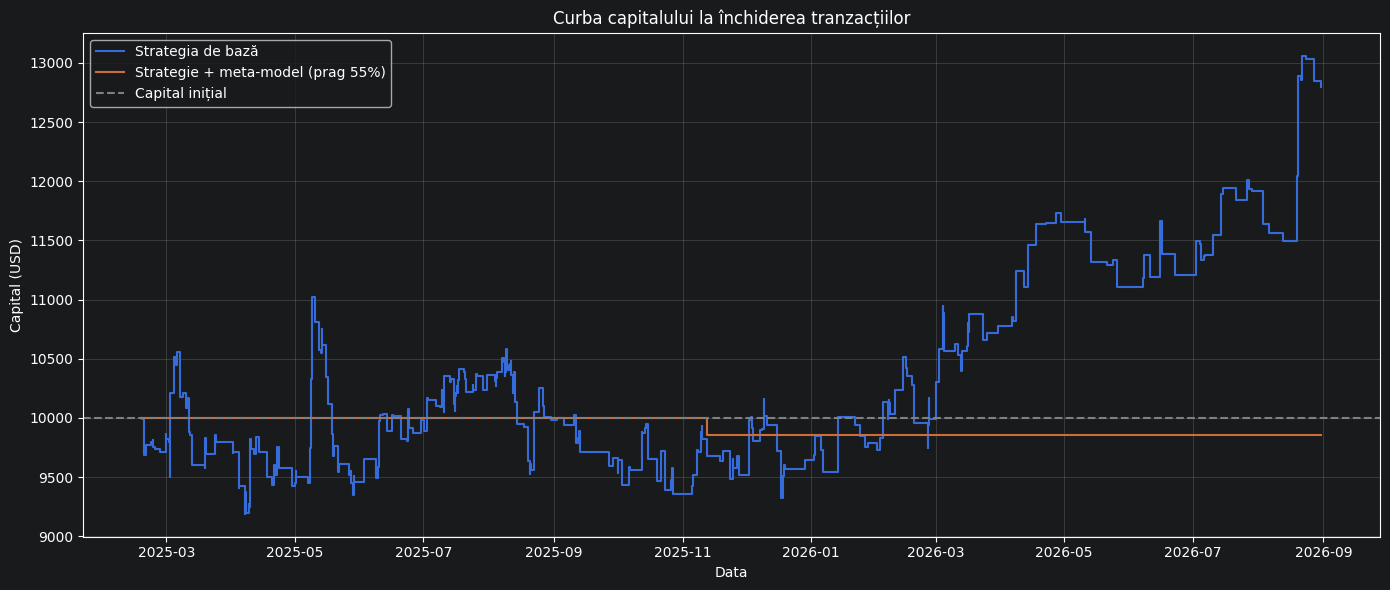

In [152]:
# economics: the source notebook's function, called unchanged (one figure per distinct threshold)
summaries = {}
for thr in sorted({t for _, t in rules.values() if t is not None}):
    summaries[thr] = plot_strategy_equity(test_events, final_model, feature_cols=features, threshold=thr,
                                          position_size=FIXED_NOTIONAL)

In [153]:
econ_rows = []
for _, (mask, thr) in rules.items():
    econ_rows.append(summaries[0.5].iloc[0] if thr is None else summaries[thr].iloc[1])
econ = pd.DataFrame(econ_rows, index=list(rules)).rename(columns={
    "Capital final (USD)": "final capital (USD)", "PnL net (USD)": "net PnL (USD, fixed-notional event PnL)",
    "Tranzacții": "retained trades", "Semnale păstrate (%)": "signals kept (%)", "Win rate net (%)": "net win rate (%)",
    "Randament mediu net (%)": "mean net return (%)"})

# consistency checks (structure, not results): the selection score on the test set equals the function's PnL; counts and win rate agree
for (label, (mask, _)), (_, r) in zip(rules.items(), econ.iterrows()):
    assert np.isclose(pnl_score(mask, pnl_test), r["net PnL (USD, fixed-notional event PnL)"], atol=1e-6), label
    assert int(mask.sum()) == int(r["retained trades"]), label
    if mask.any():
        assert np.isclose(r["net win rate (%)"] / 100, test_clf.loc[label, "precision"]), label

final_table = pd.concat([test_clf[["precision", "recall", "f1", "accuracy", "acceptance_rate"]], econ], axis=1)
final_table.round(4)

,precision,recall,f1,accuracy,acceptance_rate,final capital (USD),"net PnL (USD, fixed-notional event PnL)",retained trades,signals kept (%),net win rate (%),mean net return (%)
Unfiltered primary strategy,0.4878,1.000,0.6557,0.4878,1.0000,12795.2567,2795.2567,328.0,100.0000,48.7805,0.0852
CatBoost @ 0.50,0.5714,0.325,0.4143,0.5518,0.2774,12061.0266,2061.0266,91.0,27.7439,57.1429,0.2265
CatBoost @ 0.55 (selected),0.0000,0.000,0.0000,0.5091,0.0030,9858.6560,-141.3440,1.0,0.3049,0.0000,-1.4134


### Reading the final test

The code cell below only restates numbers that were computed above. Caveats that apply regardless of the outcome:

* the test set is one chronological block of trades: differences of a handful of trades or a few points of win rate can be well inside sampling noise, and no confidence intervals are computed here;
* the win rate of a retained set equals its precision (both use `trade_return > 0`); with zero retained trades win rate and mean return are undefined (NaN);
* the development OOF PnL values were used to pick the rule, so they are selection statistics (a maximum over several candidates); the test row of the selected rule is the only number not used for selection;
* the PnL is a fixed-notional **sum of event PnLs**, not a capital-constrained portfolio return: rejected trades contribute zero and no capital is redeployed or compounded;
* F1, precision, recall and log loss are diagnostics; the selection score was PnL only.

In [154]:
b = final_table.iloc[0]
PNL = "net PnL (USD, fixed-notional event PnL)"
if SELECTED_KIND == "model":
    print(f"Selected on development (OOF): {SEL_MODEL} @ {SEL_THR:.2f}; OOF net PnL {best['oof_net_pnl']:,.2f} USD "
          f"vs accept-all {ACCEPT_ALL_PNL:,.2f} USD and reject-all 0.00 USD (acceptance {best['acceptance_rate']:.1%})")
else:
    print(f"Selected on development (OOF): {best['model']} (OOF net PnL {best['oof_net_pnl']:,.2f} USD; accept-all {ACCEPT_ALL_PNL:,.2f} USD)."
          f" No model x threshold pair was selected; reference model for the 0.5 row: {REF_MODEL}.")
print()
for label, r in final_table.iterrows():
    wr = "  n/a" if pd.isna(r["net win rate (%)"]) else f"{r['net win rate (%)']:5.1f}%"
    print(f"final test | {label[:70]:70s} | trades {int(r['retained trades']):3d} | win rate {wr} | F1 {r['f1']:.3f} "
          f"| net PnL {r[PNL]:10.2f} USD")
print()
print("Development numbers are selection statistics; the final-test rows are one evaluation of the frozen configuration. "
      "PnL = fixed-notional event PnL, not portfolio return.")

Selected on development (OOF): CatBoost @ 0.55; OOF net PnL 316.72 USD vs accept-all -4,762.09 USD and reject-all 0.00 USD (acceptance 3.1%)

final test | Unfiltered primary strategy                                            | trades 328 | win rate  48.8% | F1 0.656 | net PnL    2795.26 USD
final test | CatBoost @ 0.50                                                        | trades  91 | win rate  57.1% | F1 0.414 | net PnL    2061.03 USD
final test | CatBoost @ 0.55 (selected)                                             | trades   1 | win rate   0.0% | F1 0.000 | net PnL    -141.34 USD

Development numbers are selection statistics; the final-test rows are one evaluation of the frozen configuration. PnL = fixed-notional event PnL, not portfolio return.
